# Loading and exploring a well

Everything starts with a `Well`. The library reads the two formats you actually meet in practice, LAS (ASCII curves) and DLIS (the binary format used for image and array tools), and gives you the same object either way.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
WELL = REPO / "src" / "petrophys" / "datasets" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
well = read_las(WELL)
well.curves[:14]

['LITHOLOGY_GEOLINK',
 'CALI',
 'DRHO',
 'NPHI',
 'RHOB',
 'PEF',
 'GR',
 'DTC',
 'DTE',
 'RDEP',
 'SP',
 'RSHA',
 'RMED',
 'BS']

Curve names are a mess in real data: bulk density might be logged as `RHOB`, `RHOZ`, `ZDEN`, or `DEN`, and neutron porosity as `NPHI`, `TNPH`, or `CNL`, depending on the vendor and the run. The library keeps the original mnemonics but also maps these aliases to standard names, so you can ask for `RHOB` or `NPHI` and get the right curve whatever the LAS called it. It does not lump together curves that only look similar: a total gamma ray (`GR`, `GRD`) and the uranium-free computed gamma ray (`CGR`) stay separate, because they measure different things. Pull the numbers out with `get`:

In [2]:
import numpy as np
gr = well.get("GR")
print("mnemonic:", gr.mnemonic, "| unit:", gr.unit)
print("depth range:", round(float(np.nanmin(well.depth)), 1), "-", round(float(np.nanmax(well.depth)), 1), well.depth_unit)
np.asarray(gr.data)[:6].round(1)

mnemonic: GR | unit: gAPI
depth range: 176.6 - 3556.1 m


array([ 9.6,  9.5,  9.5, 11.9, 12.6, 12.9])

A quick look at three raw curves, each on its own scale: gamma ray (lithology), bulk density,
and neutron porosity. Density and neutron carry the porosity signal, but they're in different
units, g/cm³ and a porosity fraction, so they go in separate tracks. (The conventional
density-neutron *overlay*, where the two are scaled to read together, is in the visualization
notebook.) Neutron is drawn high-to-low, the usual convention so it reads alongside density:

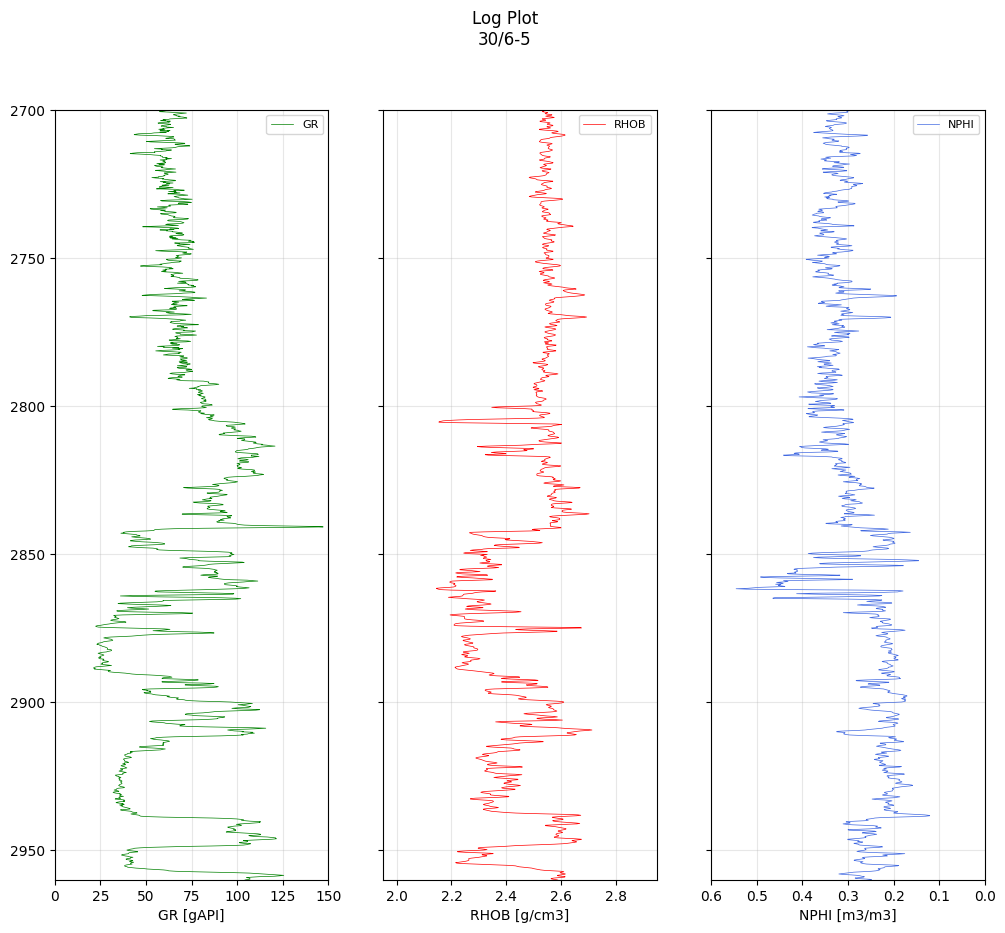

In [3]:
from petrophys.visualization import create_log_plot
create_log_plot(well, depth_range=(2700, 2960), curves=[
    {"track": 0, "name": "GR", "color": "green", "xlim": (0, 150)},
    {"track": 1, "name": "RHOB", "color": "red", "xlim": (1.95, 2.95)},
    {"track": 2, "name": "NPHI", "color": "royalblue", "xlim": (0.6, 0.0)},
]);

From here you can compute each property yourself (notebooks `03`–`08`) or hand the well to the
workflow and get everything at once, which is the next notebook.